# Anggota Kelompok

Maydian Ratu Valencia (25031554121)

Faris Riky Pratam (25031554176)

Dalilah Putri Rahma (25031554239)

# Import Depedencies

In [193]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

plt.rcParams.update({
    'figure.dpi': 120, 'font.size':11,
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False
})

In [194]:
def route(nama):
    for dirpath, _, filenames in os.walk('data/'):
        if nama in filenames:
            return os.path.join(dirpath, nama)

class CFG:
    SEED = 42
    nama_data = 'Online_Retail.xlsx'

# Tahap 1: Persiapan data

## Dataset Online Retail (UCI Machine Learning Repository)

### 1. Sumber Dataset

| Atribut | Keterangan |
|---|---|
| **Nama Dataset** | Online Retail |
| **Repositori** | UCI Machine Learning Repository (ID: 352) |
| **Pembuat/Donatur** | Daqing Chen, School of Engineering, London South Bank University |
| **Tanggal Donasi** | 5 November 2015 |
| **DOI** | [10.24432/C5BW33](https://doi.org/10.24432/C5BW33) |
| **Lisensi** | Creative Commons Attribution 4.0 International (CC BY 4.0) |
| **Format File** | `Online Retail.xlsx` (±22,6 MB) |
| **Karakteristik** | Multivariate, Sequential, Time-Series |
| **Area Subjek** | Bisnis |
| **Tugas Terkait** | Classification, Clustering |

**Deskripsi singkat:** Dataset ini berisi data transaksi yang terjadi antara **1 Desember 2010 dan 9 Desember 2011** dari sebuah perusahaan ritel *online* tanpa toko fisik yang terdaftar di Inggris (UK). Perusahaan ini terutama menjual hadiah unik untuk berbagai acara, dan banyak pelanggannya adalah **pedagang grosir (wholesaler)**.

**Sitasi (APA):**
> Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

**Makalah pengantar:** Chen, D., Sain, S. L., & Guo, K. (2012). *Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining.* Journal of Database Marketing and Customer Strategy Management, 19(3).

**Tautan:** https://archive.ics.uci.edu/dataset/352/online+retail

---

### 2. Konteks Permasalahan: Segmentasi Pelanggan (Customer Segmentation)

#### Latar Belakang
Pada bisnis ritel *online*, pelanggan memiliki perilaku belanja yang sangat beragam. Ada yang sering membeli dalam jumlah besar, ada yang hanya sekali membeli, dan ada pula yang sudah lama tidak aktif. Memperlakukan semua pelanggan dengan strategi pemasaran yang sama tidak efisien.

#### Tujuan
Mengelompokkan pelanggan ke dalam **segmen-segmen yang homogen** berdasarkan perilaku transaksinya, sehingga perusahaan dapat:
- Menyusun strategi pemasaran yang dipersonalisasi untuk tiap segmen
- Mengidentifikasi pelanggan bernilai tinggi (*loyal/VIP customers*)
- Mendeteksi pelanggan yang berisiko berhenti (*churn*)
- Mengalokasikan anggaran promosi dan retensi dengan lebih efisien

#### Pendekatan: Model RFM + Clustering
Makalah pengantar dataset ini menggunakan model **RFM** dan *data mining* (misalnya K-Means) untuk segmentasi. Ketiga dimensi RFM diturunkan dari data transaksi:

| Dimensi | Arti | Cara Penurunan dari Dataset |
|---|---|---|
| **Recency (R)** | Seberapa baru pelanggan terakhir bertransaksi | Selisih tanggal acuan dengan `InvoiceDate` terakhir per `CustomerID` |
| **Frequency (F)** | Seberapa sering pelanggan bertransaksi | Jumlah `InvoiceNo` unik per `CustomerID` |
| **Monetary (M)** | Total nilai belanja pelanggan | Jumlah dari `Quantity × UnitPrice` per `CustomerID` |

Hasil RFM kemudian dapat di-*cluster* menggunakan algoritma seperti **K-Means**, **Hierarchical Clustering**, atau **DBSCAN** untuk membentuk segmen pelanggan.

---

### 3. Jumlah Observasi

| Item | Jumlah |
|---|---|
| **Jumlah Instances (baris)** | **541.909** |
| **Jumlah Features** | 6 (menurut UCI; total kolom pada tabel variabel adalah 8, termasuk 2 kolom ber-role ID) |
| **Periode Data** | 01/12/2010 – 09/12/2011 |
| **Missing Values** | Tertulis "No" pada halaman UCI |

---

### 4. Fitur yang Digunakan

#### Daftar Variabel

| Variabel | Role | Tipe | Deskripsi | Satuan |
|---|---|---|---|---|
| `InvoiceNo` | ID | Kategorikal | Nomor faktur 6 digit yang unik untuk tiap transaksi. Jika diawali huruf **'C'**, berarti **pembatalan** | – |
| `StockCode` | ID | Kategorikal | Kode produk 5 digit yang unik untuk tiap produk | – |
| `Description` | Feature | Kategorikal | Nama produk | – |
| `Quantity` | Feature | Integer | Jumlah tiap produk per transaksi | unit |
| `InvoiceDate` | Feature | Date | Tanggal dan waktu transaksi dibuat | – |
| `UnitPrice` | Feature | Continuous | Harga per unit produk | Poundsterling (£) |
| `CustomerID` | Feature | Kategorikal | Nomor pelanggan 5 digit yang unik untuk tiap pelanggan | – |
| `Country` | Feature | Kategorikal | Nama negara tempat pelanggan berdomisili | – |

#### Fitur yang Relevan untuk Segmentasi Pelanggan

**Fitur utama (untuk membangun RFM):**
- `CustomerID`: kunci agregasi, satu baris hasil = satu pelanggan
- `InvoiceNo`: menghitung **Frequency**
- `InvoiceDate`: menghitung **Recency**
- `Quantity` dan `UnitPrice`: menghitung **Monetary** (`TotalPrice = Quantity × UnitPrice`)

**Fitur yang Digunakan:**
- `Recency`: Seberapa lama sejak transaksi terakhir
- `Frequency`: Seberapa sering customer bertransaksi
- `Monetary`: Total uang yang dikeluarkan

---

### Ringkasan

| Aspek | Ringkasan |
|---|---|
| **Sumber** | UCI ML Repository, Daqing Chen (London South Bank University), CC BY 4.0 |
| **Domain** | Ritel online di UK, menjual hadiah, banyak pelanggan grosir |
| **Periode** | 1 Des 2010 – 9 Des 2011 |
| **Observasi** | 541.909 baris transaksi |
| **Masalah** | Segmentasi pelanggan berbasis RFM dan clustering |
| **Fitur kunci** | `CustomerID`, `InvoiceNo`, `InvoiceDate`, `Quantity`, `UnitPrice` |


In [195]:
df = pd.read_excel(route(CFG.nama_data))

In [196]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Check Data Overview

In [197]:
overview = pd.DataFrame({
    'column_name': df.columns.values,
    'data_type': df.dtypes.values,
    'missing_value(%)': df.isna().mean().values * 100,
    'negative_value(%)': [len(df[col][df[col] < 0]) / df.shape[0] * 100 if col in df.select_dtypes(include=[np.number]).columns else 0 for col in df.columns],
    'duplicates': df.duplicated().sum(),
    'unique': df.nunique().values,
    'value': [df[col].unique() for col in df.columns]
})
display(overview)

,column_name,data_type,missing_value(%),negative_value(%),duplicates,unique,value
0,InvoiceNo,object,0.000000,0.000000,5268,25900,"[536365, 536366, 536367, 536368, 536369, 53637..."
1,StockCode,object,0.000000,0.000000,5268,4070,"[85123A, 71053, 84406B, 84029G, 84029E, 22752,..."
2,Description,object,0.268311,0.000000,5268,4223,"[WHITE HANGING HEART T-LIGHT HOLDER, WHITE MET..."
3,Quantity,int64,0.000000,1.960477,5268,722,"[6, 8, 2, 32, 3, 4, 24, 12, 48, 18, 20, 36, 80..."
4,InvoiceDate,datetime64[ns],0.000000,0.000000,5268,23260,"[2010-12-01 08:26:00, 2010-12-01 08:28:00, 201..."
5,UnitPrice,float64,0.000000,0.000369,5268,1630,"[2.55, 3.39, 2.75, 7.65, 4.25, 1.85, 1.69, 2.1..."
6,CustomerID,float64,24.926694,0.000000,5268,4372,"[17850.0, 13047.0, 12583.0, 13748.0, 15100.0, ..."
7,Country,object,0.000000,0.000000,5268,38,"[United Kingdom, France, Australia, Netherland..."


## Handle Missing, Negative, and Invalid Data

Pada tahap ini, dilakukan penanganan data hilang (*missing values*) dan data bernilai negatif (*negative values*). Penanganan data negatif dilakukan dengan mengubah nilai negatif menjadi nilai absolut menggunakan fungsi `abs()` pada fitur Quantity dan UnitPrice. Selain itu, baris data yang tidak memiliki CustomerID dihapus dari DataFrame karena identitas pelanggan diperlukan dalam proses pengelompokan transaksi dan perhitungan fitur RFM.

In [198]:
# Handle Negative Value
df['Quantity'] = df['Quantity'].abs()
df['UnitPrice'] = df['UnitPrice'].abs()

df['Amount'] = df['Quantity'] * df['UnitPrice']
df['Date'] = df['InvoiceDate'].dt.date
df['Time'] = df['InvoiceDate'].dt.time

# Handle Missing Value
df = df.dropna(subset=['CustomerID'])

# Sorting
df = df.sort_values(by=['CustomerID'])

## Feature Engineering

In [199]:
today = df['InvoiceDate'].max()
df['Recency'] = (today - df['InvoiceDate']).dt.days

rfm = df.groupby('CustomerID').agg({
    'Recency': 'min',
    'InvoiceNo': 'count',
    'Amount': 'sum'
}).rename(columns={
    'InvoiceNo': 'Frequency',
    'Amount': 'Monetary'
})

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,2,154367.20
12347.0,1,182,4310.00
12348.0,74,31,1797.24
12349.0,18,73,1757.55
12350.0,309,17,334.40


## Handle Outlier

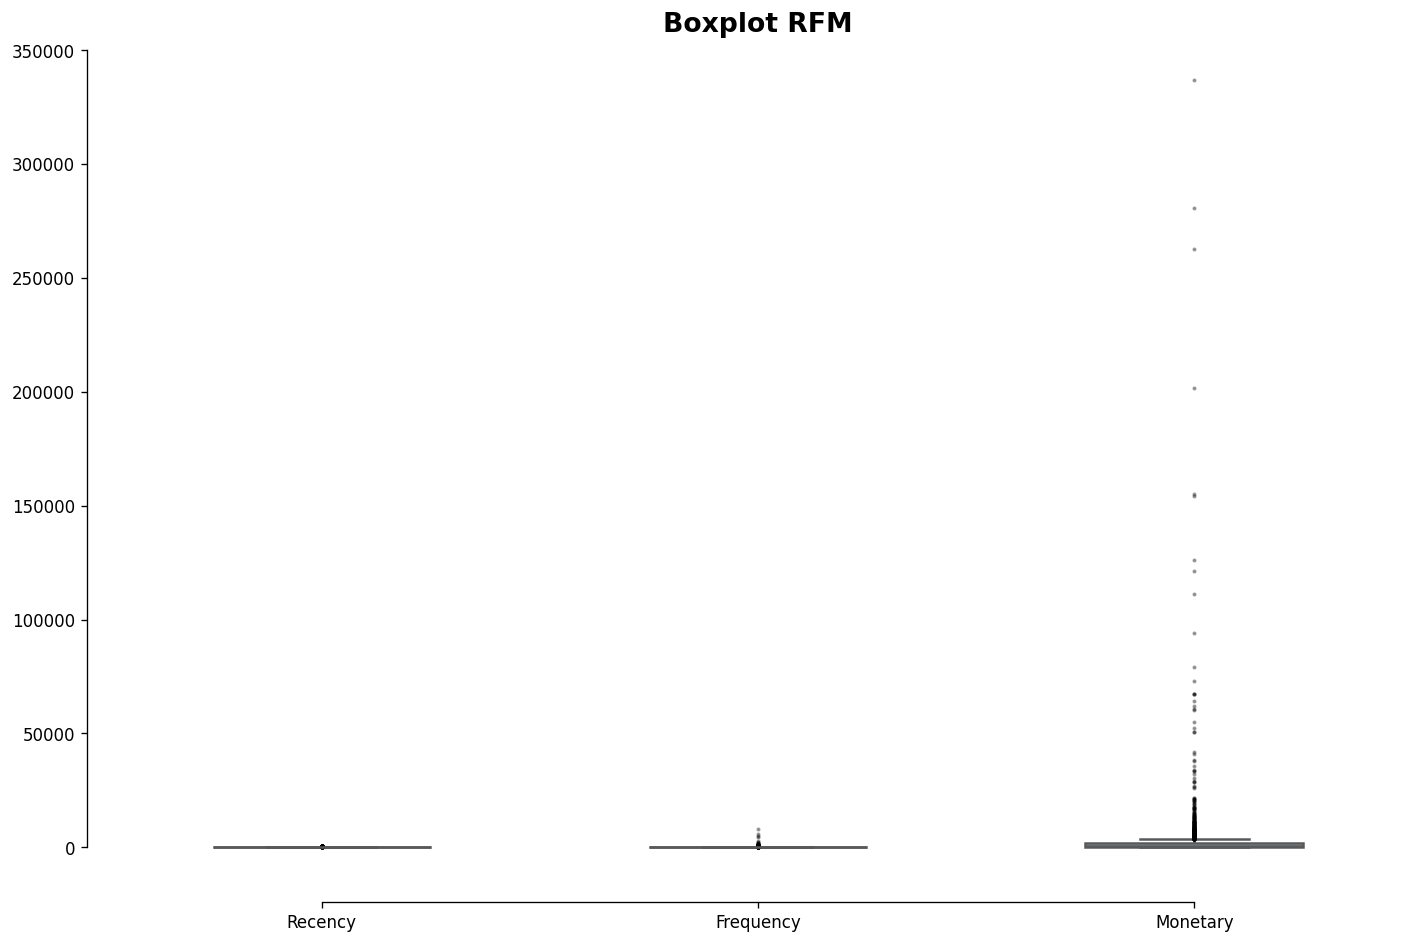

In [200]:
cols = ['Recency', 'Frequency', 'Monetary']
plt.figure(figsize=(12, 8))
ax = sns.boxplot(
    data=rfm[cols], palette=sns.color_palette("Set2", 3),
    width=0.5, linewidth=1.5,
    flierprops=dict(
        marker='.', markersize=3, alpha=0.3,
        markerfacecolor='black', markeredgecolor='black'
    )
)
ax.set_title("Boxplot RFM", fontsize=16, weight="bold")
sns.despine(offset=10, trim=True)
plt.tight_layout()
plt.show()

In [201]:
def handle_outlier(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    iqr = Q3 - Q1
    lower_bound = Q1 - 1.5 * iqr
    upper_bound = Q3 + 1.5 * iqr

    condition = (data[col] < lower_bound) | (data[col] > upper_bound)
    outlier = data[condition]
    print('Amount of Outlier:')
    print(outlier[col].count())

    no_outlier = data[~condition]

    return no_outlier.reset_index(drop=True)

for col in ['Recency', 'Frequency', 'Monetary']:
    rfm = handle_outlier(rfm, col)

Amount of Outlier:
149
Amount of Outlier:
373
Amount of Outlier:
313


## Feature Scaling & Dimensionality Reduction

Pada tahap ini, dilakukan proses standardisasi data menggunakan metode StandardScaler untuk menyamakan skala antarfitur sehingga setiap fitur memiliki kontribusi yang seimbang dalam proses clustering. Standardisasi dilakukan dengan mengubah nilai setiap fitur agar memiliki rata-rata (mean) sebesar 0 dan standar deviasi sebesar 1. Dengan demikian, perbedaan rentang nilai antarfitur RFM dapat diminimalkan sehingga tidak ada fitur yang mendominasi proses pengelompokan akibat perbedaan skala data.

In [202]:
cluster_cols = ['Recency', 'Frequency', 'Monetary']
X = rfm[cluster_cols].copy()

preprocessor = Pipeline(
    [
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=2, random_state=42))
    ]
)

X_scaled = pd.DataFrame(preprocessor.fit_transform(X), columns=['PCA_1', 'PCA_2'])

In [203]:
X_som = X_scaled.to_numpy()

# Tahap 2: Implementasi Self-Organizing Map (SOM)

In [204]:
class SOM:
    def __init__(self, baris=20, kolom=20, lr=0.5, sigma=None, epochs=20, seed=1):
        self.baris = baris
        self.kolom = kolom
        self.lr = lr
        self.sigma = sigma
        self.epochs = epochs
        self.seed = seed

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        jumlah_data, jumlah_fitur = X.shape
        self.bobot = rng.uniform(X.min(axis=0), X.max(axis=0), (self.baris, self.kolom, jumlah_fitur))
        if self.sigma is None:
            self.sigma = max(self.baris, self.kolom) / 2
        grid = np.array([(posisi_baris, posisi_kolom)
                         for posisi_baris in range(self.baris)
                         for posisi_kolom in range(self.kolom)])
        total = self.epochs * jumlah_data
        for langkah in range(total):
            x = X[rng.integers(jumlah_data)]
            progres = langkah / max(total -1, 1)
            learning_rate = self.lr * (1 - progres)
            sigma = max(0.5, self.sigma * (1 -progres))
            jarak = np.linalg.norm(self.bobot - x, axis=2)
            koordinat_neuron = np.unravel_index(np.argmin(jarak), jarak.shape)
            koordinat_neuron_array = np.array(koordinat_neuron)
            jarak_grid = np.sum((grid - koordinat_neuron_array) ** 2, axis=1)
            nilai_tetangga = np.exp(-jarak_grid / (2 * sigma ** 2)).reshape(self.baris, self.kolom, 1)
            self.bobot += (learning_rate * nilai_tetangga * (x - self.bobot))
        return self
    
    def pemenang(self, X):
        jarak = np.linalg.norm(X[:, None, None, :] - self.bobot[None, :, :, :], axis=3)
        return np.array([np.unravel_index(posisi, jarak.shape[1:])
                         for posisi in jarak.reshape(len(X), -1).argmin(axis=1)])

In [205]:
som = SOM(baris=20, kolom=20, lr=0.5, sigma=None, epochs=20, seed=1)
som.fit(X_som)
hasil_pemenang = som.pemenang(X_som)

In [206]:
hasil_pemenang.shape

(3537, 2)

In [207]:
hasil_pemenang[:10]

array([[13,  7],
       [18,  9],
       [ 3,  0],
       [ 0,  6],
       [ 9,  1],
       [ 4,  5],
       [17,  4],
       [15, 19],
       [17,  1],
       [ 1,  2]])

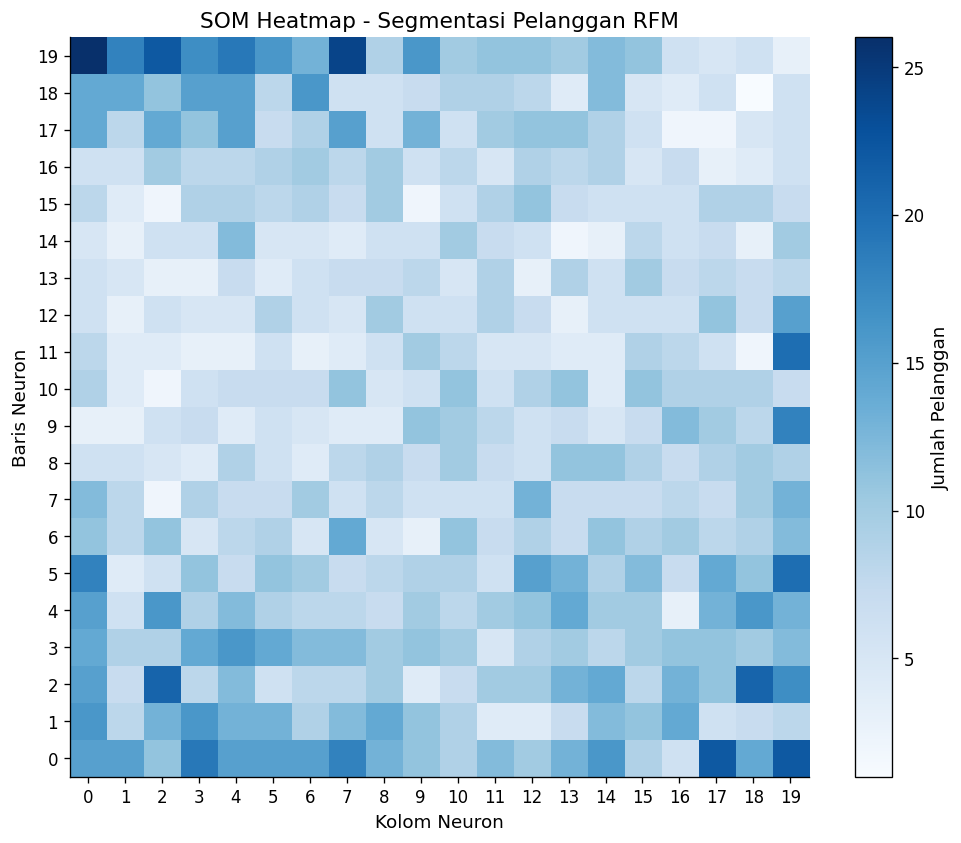

In [208]:
jumlah_pelanggan = np.zeros((som.baris, som.kolom), dtype=int)
for baris, kolom in hasil_pemenang:
    jumlah_pelanggan[baris, kolom] += 1

plt.figure(figsize=(10, 8))
plt.imshow(jumlah_pelanggan, cmap='Blues', origin='lower', interpolation='nearest')
plt.colorbar(label='Jumlah Pelanggan')
plt.title('SOM Heatmap - Segmentasi Pelanggan RFM')
plt.xlabel('Kolom Neuron')
plt.ylabel('Baris Neuron')
plt.xticks(range(som.kolom))
plt.yticks(range(som.baris))
plt.show()

In [209]:
hasil_rfm = X.copy().reset_index(drop=True)
hasil_rfm['baris_bmu'] = hasil_pemenang[:, 0]
hasil_rfm['kolom_bmu'] = hasil_pemenang[:, 1]

In [210]:
karakteristik_neuron = hasil_rfm.groupby(["baris_bmu", "kolom_bmu"]).agg(
    jumlah_pelanggan=("Recency", "size"),
    rata_recency=("Recency", "mean"),
    rata_frequency=("Frequency", "mean"),
    rata_monetary=("Monetary", "mean")).reset_index()
karakteristik_neuron.head(10)

,baris_bmu,kolom_bmu,jumlah_pelanggan,rata_recency,rata_frequency,rata_monetary
0,0,0,15,317.266667,3.933333,87.730000
1,0,1,15,293.933333,3.333333,71.266667
2,0,2,11,277.363636,4.454545,120.581818
3,0,3,19,258.894737,3.736842,74.342105
4,0,4,15,238.133333,6.400000,118.728000
5,0,5,15,217.733333,5.133333,113.964667
6,0,6,15,200.666667,5.200000,142.944000
7,0,7,18,183.444444,5.388889,96.278333
8,0,8,13,162.461538,5.923077,100.698462
9,0,9,11,139.545455,3.818182,120.610909


In [211]:
u_matrix = np.zeros((som.baris, som.kolom))

for baris in range(som.baris):
    for kolom in range(som.kolom):
        tetangga = []

        for i in range(-1, 2):
            for j in range(-1, 2):
                if i == 0 and j == 0:
                    continue

                b = baris + i
                k = kolom + j

                if 0 <= b < som.baris and 0 <= k < som.kolom:
                    jarak = np.linalg.norm(som.bobot[baris, kolom] - som.bobot[b, k])
                    tetangga.append(jarak)

        u_matrix[baris, kolom] = np.mean(tetangga)

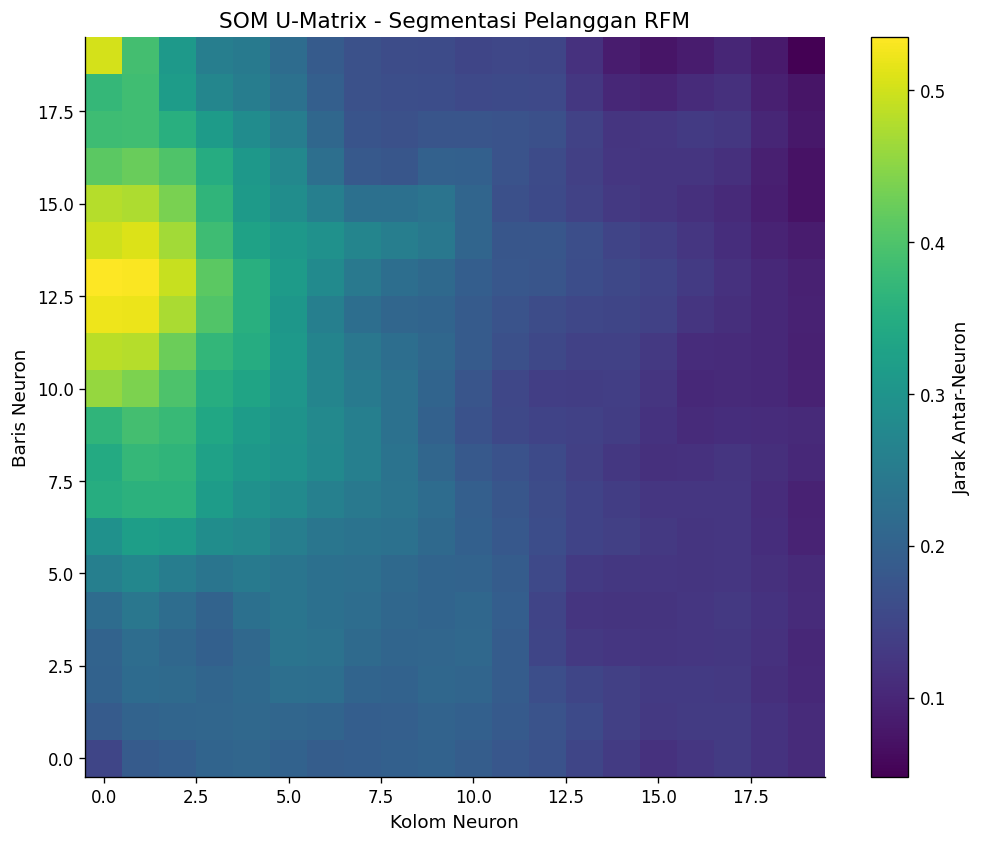

In [212]:
plt.figure(figsize=(10, 8))
plt.imshow(u_matrix, cmap='viridis', origin='lower', interpolation='nearest')
plt.colorbar(label='Jarak Antar-Neuron')
plt.title('SOM U-Matrix - Segmentasi Pelanggan RFM')
plt.xlabel('Kolom Neuron')
plt.ylabel('Baris Neuron')
plt.show()

In [213]:
print("Jarak minimum:", u_matrix.min())
print("Jarak maksimum:", u_matrix.max())
print("Rata-rata jarak:", u_matrix.mean())

Jarak minimum: 0.04796608268765016
Jarak maksimum: 0.5348859642884258
Rata-rata jarak: 0.20732057081798572


# Tahap 3: Clustering menggunakan SOM + K-Means

## Ambil Vector Bobot

In [214]:
neuron_criteria = np.unique(hasil_pemenang, axis=0)
prototipe = np.array([som.bobot[baris, kolom] for baris, kolom in neuron_criteria])

print('Jumlah neuron terpakai:', len(neuron_criteria))
print('Jumlah prototipe:', len(prototipe))
print('Dimensi prototipe:', prototipe.shape)

Jumlah neuron terpakai: 400
Jumlah prototipe: 400
Dimensi prototipe: (400, 2)


## Penerapan Bobot pada KMeans

K Optimization: 100%|██████████| 10/10 [00:00<00:00, 27.83it/s]


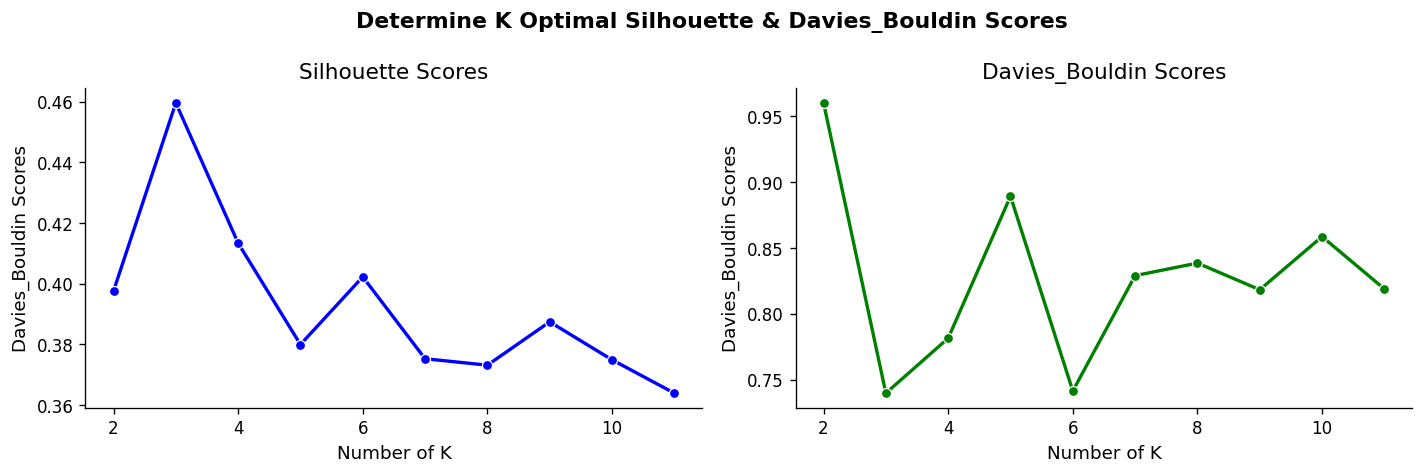

In [215]:
k_range = range(2, 12)
silhouette, db_scores = [], []
for i in tqdm(k_range, desc='K Optimization'):
    model = KMeans(n_clusters=i, random_state=CFG.SEED)
    label = model.fit_predict(prototipe)
    silhouette.append(silhouette_score(prototipe, label))
    db_scores.append(davies_bouldin_score(prototipe, label))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Determine K Optimal Silhouette & Davies_Bouldin Scores', fontweight='bold')
for i, eval in enumerate([silhouette, db_scores]):
    color = 'blue' if eval == silhouette else 'green'
    title = 'Silhouette Scores' if eval == silhouette else 'Davies_Bouldin Scores'
    sns.lineplot(x=list(k_range), y=eval, color=color, marker='o', linewidth=2, markersize=6, ax=ax[i])
    ax[i].set_title(title)
    ax[i].set_xlabel('Number of K')
    ax[i].set_ylabel('Davies_Bouldin Scores')
plt.tight_layout()
plt.show()

## Label Seluruh Data Observasi berdasarkan BMU

In [216]:
model = KMeans(n_clusters=3, random_state=CFG.SEED)
label = model.fit_predict(prototipe)

mapping_label = {tuple(posisi): label for posisi, label in zip(neuron_criteria, label)}
hasil_pemenang_cluster = np.array([mapping_label[tuple(posisi)] for posisi in hasil_pemenang])

print("Jumlah prototipe:", len(prototipe))
print("Label cluster data:", hasil_pemenang_cluster)
print('Jumlah Akhir Label:', len(hasil_pemenang_cluster))

Jumlah prototipe: 400
Label cluster data: [1 1 2 ... 2 0 1]
Jumlah Akhir Label: 3537


## Visualisasi Hasil Cluster pada Peta SOM & Penjelasan Karakteristik

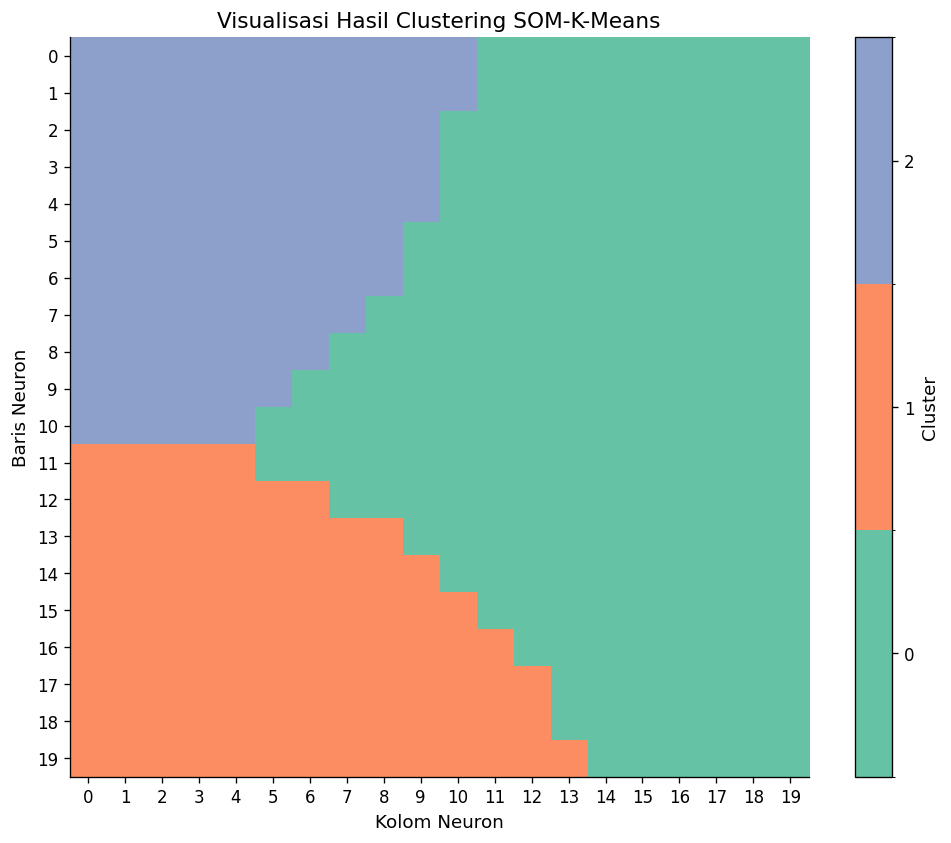

In [217]:
mapping_cluster_res_3 = np.full((som.baris, som.kolom), np.nan)
for posisi, cluster in zip(neuron_criteria, label):
    baris, kolom = posisi
    mapping_cluster_res_3[baris, kolom] = cluster

jumlah_cluster = len(np.unique(label))
warna = sns.color_palette('Set2', jumlah_cluster)
cmap = ListedColormap(warna)
batas = np.arange(-0.5, jumlah_cluster + 0.5, 1)
norm = BoundaryNorm(batas, cmap.N)

plt.figure(figsize=(10, 8))
plt.imshow(mapping_cluster_res_3, cmap=cmap, norm=norm, interpolation='nearest', aspect='equal')
plt.colorbar(ticks=np.arange(jumlah_cluster), label='Cluster')

plt.title('Visualisasi Hasil Clustering SOM-K-Means')
plt.xlabel('Kolom Neuron')
plt.ylabel('Baris Neuron')
plt.xticks(range(som.kolom))
plt.yticks(range(som.baris))
plt.show()

Berdasarkan hasil visualisasi clustering SOM-K-Means, diperoleh tiga kelompok cluster yang memiliki pola persebaran berbeda pada peta SOM berukuran 20 × 20 neuron.

### 1. Karakteristik Setiap Cluster

- **Cluster 0 (Hijau Toska)**

  Cluster 0 memiliki wilayah persebaran paling luas dan mendominasi bagian kanan peta SOM. Persebarannya mencakup area kanan atas hingga kanan bawah serta sebagian wilayah tengah. Hal ini menunjukkan bahwa sebagian besar neuron pada wilayah tersebut memiliki karakteristik prototipe yang relatif serupa berdasarkan hasil pengelompokan K-Means.

- **Cluster 1 (Oranye)**

  Cluster 1 terkonsentrasi pada bagian kiri bawah peta SOM, terutama pada baris neuron sekitar 11–19. Wilayah cluster ini memiliki batas persebaran yang cenderung diagonal terhadap Cluster 0. Hal ini menunjukkan adanya kelompok neuron dengan karakteristik prototipe yang berbeda dari cluster lainnya.

- **Cluster 2 (Biru)**

  Cluster 2 terkonsentrasi pada bagian kiri atas peta SOM, terutama pada baris neuron sekitar 0–10. Cluster ini memiliki wilayah yang berdekatan dengan Cluster 1 di bagian bawah dan Cluster 0 di bagian kanan. Persebarannya menunjukkan adanya kelompok neuron dengan karakteristik prototipe yang relatif serupa.

### 2. Kesimpulan

Hasil clustering SOM-K-Means menghasilkan tiga cluster dengan karakteristik persebaran yang berbeda. Cluster 0 mendominasi wilayah kanan peta SOM, Cluster 1 terkonsentrasi di bagian kiri bawah, sedangkan Cluster 2 terkonsentrasi di bagian kiri atas. Pemisahan wilayah tersebut menunjukkan bahwa neuron SOM berhasil dikelompokkan berdasarkan kemiripan karakteristik prototipenya.